Repository links
- Your txtai fork
- Original txtai repository
- Introducing txtai notebook
- Agent quickstart
- RAG quickstart

# Introducing txtai — Fixed

[txtai](https://github.com/neuml/txtai) is an all-in-one AI framework for semantic search, LLM orchestration and language model workflows.

The key component of txtai is an embeddings database, which is a union of vector indexes (sparse and dense), graph networks and relational databases.

This foundation enables vector search and/or serves as a powerful knowledge source for large language model (LLM) applications.

Build autonomous agents, retrieval augmented generation (RAG) processes, multi-model workflows and more.

The following is a summary of key features:

- 🔎 Vector search with SQL, object storage, topic modeling, graph analysis and multimodal indexing
- 📄 Create embeddings for text, documents, audio, images and video
- 💡 Pipelines powered by language models that run LLM prompts, question-answering, labeling, transcription, translation, summarization and more
- ↪️️ Workflows to join pipelines together and aggregate business logic. txtai processes can be simple microservices or multi-model workflows.
- 🤖 Agents that intelligently connect embeddings, pipelines, workflows and other agents together to autonomously solve complex problems
- ⚙️ Web and Model Context Protocol (MCP) APIs. Bindings available for [JavaScript](https://github.com/neuml/txtai.js), [Java](https://github.com/neuml/txtai.java), [Rust](https://github.com/neuml/txtai.rs) and [Go](https://github.com/neuml/txtai.go).
- 🔋 Batteries included with defaults to get up and running fast
- ☁️ Run local or scale out with container orchestration

txtai is built with Python 3.11+, [Hugging Face Transformers](https://github.com/huggingface/transformers), [Sentence Transformers](https://github.com/UKPLab/sentence-transformers) and [FastAPI](https://github.com/tiangolo/fastapi). txtai is open-source under an Apache 2.0 license.

> [NeuML](https://neuml.com) is the company behind txtai and we provide AI consulting services around our stack. [Schedule a meeting](https://cal.com/neuml/intro) or [send a message](mailto:info@neuml.com) to learn more.
>
> We're also building an easy and secure way to run hosted txtai applications with [txtai.cloud](https://txtai.cloud).


# Install dependencies

Install `txtai` with graph/topic-modeling support. The notebook uses current txtai configuration and workflow syntax.


In [1]:
%%capture
# Install txtai with graph/topic-modeling support.
# The default txtai install already includes the common translation workflow dependencies.
%pip install "txtai[graph]"


# Semantic search

Embeddings databases are the engine that delivers semantic search. Data is transformed into embeddings vectors where similar concepts will produce similar vectors. Indexes both large and small are built with these vectors. The indexes are used to find results that have the same meaning, not necessarily the same keywords.

The basic use case for an embeddings database is building an approximate nearest neighbor (ANN) index for semantic search. The following example indexes a small number of text entries to demonstrate the value of semantic search.


In [2]:
%%capture

from txtai import Embeddings

# Works with a list, dataset or generator
data = [
  "US tops 5 million confirmed virus cases",
  "Canada's last fully intact ice shelf has suddenly collapsed, forming a Manhattan-sized iceberg",
  "Beijing mobilises invasion craft along coast as Taiwan tensions escalate",
  "The National Park Service warns against sacrificing slower friends in a bear attack",
  "Maine man wins $1M from $25 lottery ticket",
  "Make huge profits without work, earn up to $100,000 a day"
]

# Create an embeddings
embeddings = Embeddings(path="sentence-transformers/all-MiniLM-L6-v2")

In [3]:
# Create an index for the list of text
embeddings.index(data)

print("%-20s %s" % ("Query", "Best Match"))
print("-" * 50)

# Run an embeddings search for each query
for query in ("feel good story", "climate change", "public health story", "war", "wildlife", "asia", "lucky", "dishonest junk"):
  # Extract uid of first result
  # search result format: (uid, score)
  uid = embeddings.search(query, 1)[0][0]

  # Print text
  print("%-20s %s" % (query, data[uid]))

Query                Best Match
--------------------------------------------------
feel good story      The National Park Service warns against sacrificing slower friends in a bear attack
climate change       The National Park Service warns against sacrificing slower friends in a bear attack
public health story  The National Park Service warns against sacrificing slower friends in a bear attack
war                  Beijing mobilises invasion craft along coast as Taiwan tensions escalate
wildlife             The National Park Service warns against sacrificing slower friends in a bear attack
asia                 Beijing mobilises invasion craft along coast as Taiwan tensions escalate
lucky                Maine man wins $1M from $25 lottery ticket
dishonest junk       Make huge profits without work, earn up to $100,000 a day


The example above shows that for all of the queries, the query text isn’t in the data. This is the true power of transformers models over token based search. What you get out of the box is 🔥🔥🔥!

# Updates and deletes

Updates and deletes are supported for embeddings. The upsert operation will insert new data and update existing data

The following section runs a query, then updates a value changing the top result and finally deletes the updated value to revert back to the original query results.

In [4]:
# Run initial query
uid = embeddings.search("feel good story", 1)[0][0]
print("Initial:", data[uid])

# Update an existing record
original = data[0]
updated = "See it: baby panda born"
embeddings.upsert([(0, updated, None)])

uid = embeddings.search("feel good story", 1)[0][0]
print("After update:", updated if uid == 0 else data[uid])

# Restore the original record so later notebook examples start from the same data
embeddings.upsert([(0, original, None)])

uid = embeddings.search("feel good story", 1)[0][0]
print("After restore:", data[uid])


Initial: The National Park Service warns against sacrificing slower friends in a bear attack
After update: The National Park Service warns against sacrificing slower friends in a bear attack
After restore: The National Park Service warns against sacrificing slower friends in a bear attack


# Persistence

Embeddings can be saved to storage and reloaded.

In [5]:
embeddings.save("index")

embeddings = Embeddings()
embeddings.load("index")

uid = embeddings.search("climate change", 1)[0][0]
print(data[uid])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

The National Park Service warns against sacrificing slower friends in a bear attack


# Hybrid search

While dense vector indexes are by far the best option for semantic search systems, sparse keyword indexes can still add value. There may be cases where finding an exact match is important.

Hybrid search combines the results from sparse and dense vector indexes for the best of both worlds.

In [6]:
# Create an embeddings
embeddings = Embeddings(hybrid=True, path="sentence-transformers/all-MiniLM-L6-v2")

# Create an index for the list of text
embeddings.index(data)

print("%-20s %s" % ("Query", "Best Match"))
print("-" * 50)

# Run an embeddings search for each query
for query in ("feel good story", "climate change", "public health story", "war", "wildlife", "asia", "lucky", "dishonest junk"):
  # Extract uid of first result
  # search result format: (uid, score)
  uid = embeddings.search(query, 1)[0][0]

  # Print text
  print("%-20s %s" % (query, data[uid]))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Query                Best Match
--------------------------------------------------
feel good story      The National Park Service warns against sacrificing slower friends in a bear attack
climate change       The National Park Service warns against sacrificing slower friends in a bear attack
public health story  The National Park Service warns against sacrificing slower friends in a bear attack
war                  Beijing mobilises invasion craft along coast as Taiwan tensions escalate
wildlife             The National Park Service warns against sacrificing slower friends in a bear attack
asia                 Beijing mobilises invasion craft along coast as Taiwan tensions escalate
lucky                Maine man wins $1M from $25 lottery ticket
dishonest junk       Make huge profits without work, earn up to $100,000 a day


Same results as with semantic search. Let's run the same example with just a keyword index to view those results.

In [7]:
# Create an embeddings
embeddings = Embeddings(keyword=True)

# Create an index for the list of text
embeddings.index(data)

print(embeddings.search("feel good story"))
print(embeddings.search("lottery"))

[]
[(4, 0.5234998733628726)]


See that when the embeddings instance only uses a keyword index, it can't find semantic matches, only keyword matches.

# Content storage

Up to this point, all the examples are referencing the original data array to retrieve the input text. This works fine for a demo but what if you have millions of documents? In this case, the text needs to be retrieved from an external datastore using the id.

Content storage adds an associated database (i.e. SQLite, DuckDB) that stores associated metadata with the vector index. The document text, additional metadata and additional objects can be stored and retrieved right alongside the indexed vectors.

In [8]:
# Create embeddings with content enabled. The default behavior is to only store indexed vectors.
embeddings = Embeddings(path="sentence-transformers/all-MiniLM-L6-v2", content=True, objects=True)

# Create an index for the list of text
embeddings.index(data)

print(embeddings.search("feel good story", 1)[0]["text"])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

The National Park Service warns against sacrificing slower friends in a bear attack


The only change above is setting the *content* flag to True. This enables storing text and metadata content (if provided) alongside the index. Note how the text is pulled right from the query result!

Let's add some metadata.

# Query with SQL

When content is enabled, the entire dictionary is stored and can be queried. In addition to vector queries, txtai accepts SQL queries. This enables combined queries using both a vector index and content stored in a database backend.

In [9]:
# Create an index for the list of text
embeddings.index([{"text": text, "length": len(text)} for text in data])

# Filter by score
print(embeddings.search("select text, score from txtai where similar('hiking danger') and score >= 0.15"))

# Filter by metadata field 'length'
print(embeddings.search("select text, length, score from txtai where similar('feel good story') and score >= 0.05 and length >= 40"))

# Run aggregate queries
print(embeddings.search("select count(*), min(length), max(length), sum(length) from txtai"))

[{'text': 'The National Park Service warns against sacrificing slower friends in a bear attack', 'score': 0.33373790979385376}]
[{'text': 'The National Park Service warns against sacrificing slower friends in a bear attack', 'length': 83, 'score': 0.12310206890106201}, {'text': 'Make huge profits without work, earn up to $100,000 a day', 'length': 57, 'score': 0.0837268978357315}, {'text': 'Beijing mobilises invasion craft along coast as Taiwan tensions escalate', 'length': 72, 'score': 0.05952081456780434}]
[{'count(*)': 6, 'min(length)': 39, 'max(length)': 94, 'sum(length)': 387}]


This example above adds a simple additional field, text length.

Note the second query is filtering on the metadata field length along with a `similar` query clause. This gives a great blend of vector search with traditional filtering to help identify the best results.

# Object storage

In addition to metadata, binary content can also be associated with documents. The example below downloads an image, upserts it along with associated text into the embeddings index.

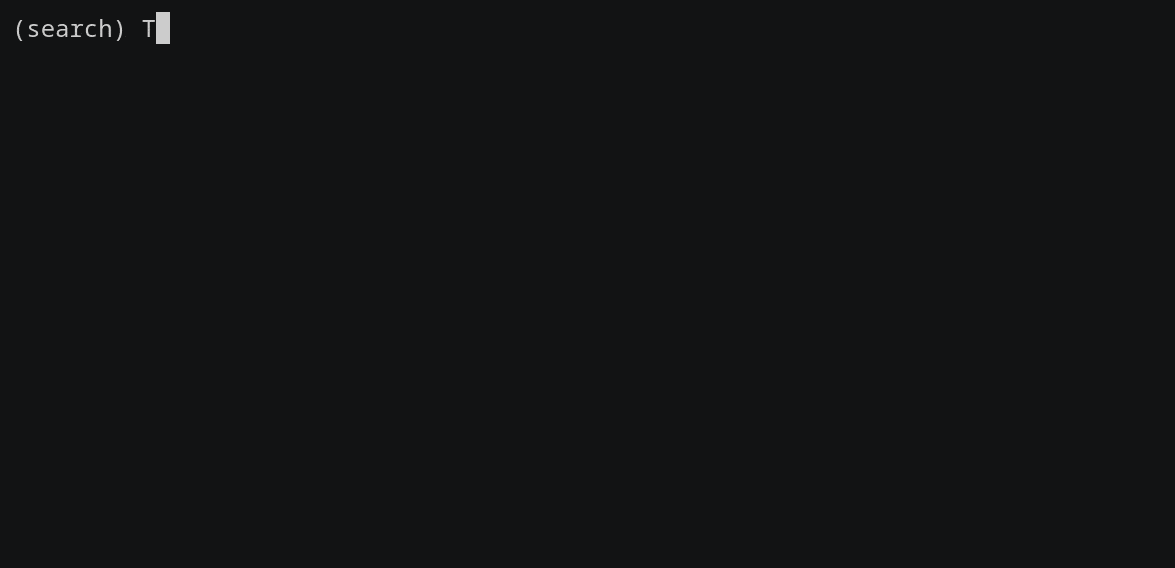

In [25]:
from io import BytesIO
from IPython.display import display, Image

# Retrieve the image
results = embeddings.search(
    """
    SELECT object
    FROM txtai
    WHERE similar('machine learning')
    LIMIT 1
    """
)

if not results:
    raise RuntimeError("No result returned from txtai.")

result = results[0]["object"]

# Convert BytesIO -> bytes
if isinstance(result, BytesIO):
    result.seek(0)
    result = result.read()

# Handle other binary types
elif isinstance(result, memoryview):
    result = result.tobytes()

elif isinstance(result, bytearray):
    result = bytes(result)

# Validate
if not isinstance(result, bytes):
    raise TypeError(
        f"Expected image bytes, but received: {type(result)}"
    )

if len(result) == 0:
    raise ValueError("The retrieved image contains no data.")

# Display image
display(Image(data=result, width=600))

# Topic modeling

Topic modeling is enabled via semantic graphs. Semantic graphs, also known as knowledge graphs or semantic networks, build a graph network with semantic relationships connecting the nodes. In txtai, they can take advantage of the relationships inherently learned within an embeddings index.

In [11]:
# Create embeddings with a graph index
embeddings = Embeddings(
  path="sentence-transformers/all-MiniLM-L6-v2",
  content=True,
  functions=[
    {"name": "graph", "function": "graph.attribute"},
  ],
  expressions=[
    {"name": "category", "expression": "graph(indexid, 'category')"},
    {"name": "topic", "expression": "graph(indexid, 'topic')"},
  ],
  graph={
    "topics": {
      "level": "first",
      "categories": ["health", "climate", "finance", "world politics"]
    }
  }
)

embeddings.index(data)
embeddings.search("select topic, category, text from txtai")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[{'topic': 'us_confirmed_virus_5',
  'category': 'health',
  'text': 'US tops 5 million confirmed virus cases'},
 {'topic': "canada's_suddenly_forming_shelf",
  'category': 'climate',
  'text': "Canada's last fully intact ice shelf has suddenly collapsed, forming a Manhattan-sized iceberg"},
 {'topic': 'taiwan_coast_along_tensions',
  'category': 'world politics',
  'text': 'Beijing mobilises invasion craft along coast as Taiwan tensions escalate'}]

When a graph index is enabled, topics are assigned to each of the entries in the embeddings instance. Topics are dynamically created using a sparse index over graph nodes grouped by [community detection algorithms](https://en.wikipedia.org/wiki/Community_structure).

Topic categories are also be derived as shown above.

# Subindexes

Subindexes can be configured for an embeddings. A single embeddings instance can have multiple subindexes each with different configurations.

We'll build an embeddings index having both a keyword and dense index to demonstrate.

In [12]:
# Create embeddings with subindexes
embeddings = Embeddings(
  content=True,
  defaults=False,
  indexes={
    "keyword": {
      "keyword": True
    },
    "dense": {
      "path": "sentence-transformers/all-MiniLM-L6-v2"
    }
  }
)
embeddings.index(data)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [13]:
embeddings.search("feel good story", limit=1, index="keyword")

[]

In [14]:
embeddings.search("feel good story", limit=1, index="dense")

[{'id': '3',
  'text': 'The National Park Service warns against sacrificing slower friends in a bear attack',
  'score': 0.12310206890106201}]

Once again, this example demonstrates the difference between keyword and semantic search. The first search call uses the defined keyword index, the second uses the dense vector index.

# LLM orchestration

txtai is an all-in-one AI framework. txtai supports building autonomous agents, retrieval augmented generation (RAG), chat with your data, pipelines and workflows that interface with large language models (LLMs).

The [RAG pipeline](https://neuml.github.io/txtai/pipeline/text/rag/) is txtai's spin on retrieval augmented generation (RAG). This pipeline extracts knowledge from content by joining a prompt, context data store and generative model together.

The following example shows how a large language model (LLM) can use an embeddings database for context.

In [15]:
from txtai import RAG

# Create embeddings
embeddings = Embeddings(path="sentence-transformers/all-MiniLM-L6-v2", content=True, autoid="uuid5")

# Create an index for the list of text
embeddings.index(data)

# RAG Prompt Template
template = """
  Answer the following question using the provided context.

  Question:
  {question}

  Context:
  {context}
"""

# Create and run RAG instance
rag = RAG(embeddings, "Qwen/Qwen3-0.6B", template=template, output="reference")
rag("What country is having issues with climate change?")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

{'answer': 'Canada is having issues with climate change.',
 'reference': 'da633124-33ff-58d6-8ecb-14f7a44c042a'}

The logic above first builds an embeddings index. It then loads a LLM and uses the embeddings index to drive a LLM prompt.

The RAG pipeline can optionally return a reference to the id of the best matching record with the answer. That id can be used to resolve the full answer reference. Note that the embeddings above used an [uuid autosequence](https://neuml.github.io/txtai/embeddings/configuration/general/#autoid).

In [16]:
uid = rag("What country is having issues with climate change?")["reference"]
embeddings.search(f"select id, text from txtai where id = '{uid}'")

[{'id': 'da633124-33ff-58d6-8ecb-14f7a44c042a',
  'text': "Canada's last fully intact ice shelf has suddenly collapsed, forming a Manhattan-sized iceberg"}]

LLM inference can also be run standalone.

In [17]:
from txtai import LLM

# Use a small instruction-tuned model for a lightweight local example.
# Models can also be supplied through Hugging Face, llama.cpp, Ollama, vLLM or LiteLLM.
llm = LLM("Qwen/Qwen3-0.6B")
llm("Say the name of 1 place to visit in Washington, DC")


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

'The White House.'

# Language model workflows

Language model workflows, also known as semantic workflows, connect language models together to build intelligent applications.

Workflows can run right alongside an embeddings instance, similar to a stored procedure in a relational database. Workflows can be written in either Python or YAML. We'll demonstrate how to write a workflow with YAML.

In [18]:
%%writefile embeddings.yml

# Embeddings instance
writable: true
embeddings:
  path: sentence-transformers/all-MiniLM-L6-v2
  content: true

# Translation pipeline
translation:

# Workflow definitions
workflow:
  search:
    tasks:
      - action: search
        task: template
        template: "select text from txtai where similar('{text}') limit 1"
      - action: translation
        args: ["fr"]


Writing embeddings.yml


The workflow above loads an embeddings index and defines a search workflow. The search workflow runs a search and then passes the results to a translation pipeline. The translation pipeline translates results to French.

In [26]:
!pip install -U "txtai[pipeline]"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.9/80.9 MB 67.8 MB/s  0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 78.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 49.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 132.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 161.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.3/27.3 MB 44.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.2/679.2 kB 29.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.1/41.1 MB 58.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 131.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 142.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.2/33.2 MB 3

In [4]:
from txtai import Application

# Use plain text documents
data = [
    "This is a feel good story about friendship and happiness.",
    "A wonderful story about helping people and spreading kindness.",
    "Machine learning is transforming modern applications.",
    "The weather was beautiful and everyone enjoyed the day."
]

# Build application
app = Application("embeddings.yml")

# Add text data
app.add(data)
app.index()

# Search directly instead of using the workflow
results = app.search("feel good story", 5)

print(results)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[{'id': '0', 'text': 'This is a feel good story about friendship and happiness.', 'score': 0.6996122598648071}, {'id': '1', 'text': 'A wonderful story about helping people and spreading kindness.', 'score': 0.49523186683654785}, {'id': '3', 'text': 'The weather was beautiful and everyone enjoyed the day.', 'score': 0.30782634019851685}, {'id': '2', 'text': 'Machine learning is transforming modern applications.', 'score': 0.08099609613418579}]


SQL functions, in some cases, can accomplish the same thing as a workflow. The function below runs the translation pipeline as a function.

In [5]:
from txtai import Application

app = Application("embeddings.yml")

print(
    app.pipeline(
        "translation",
        "This is a feel good story",
        "fr"
    )
)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  301MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  301MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


C'est une bonne histoire.


LLM chains with templates are also possible with workflows. Workflows are self-contained, they operate both with and without an associated embeddings instance. The following workflow uses a LLM to conditionally translate text to French and then detect the language of the text.

In [6]:
%%writefile workflow.yml

llm:
  path: Qwen/Qwen3-0.6B

workflow:
  chain:
    tasks:
      - task: template
        template: "Translate text '{statement}' to {language} if the text is English, otherwise keep the original text."
        action: llm
      - task: template
        template: "What language is the following text? Only print the answer: {text}"
        action: llm


Overwriting workflow.yml


In [7]:
inputs = [
  {"statement": "Hello, how are you", "language": "French"},
  {"statement": "Hallo, wie geht's dir", "language": "French"}
]

app = Application("workflow.yml")
list(app.workflow("chain", inputs))

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

['French', 'French']

# Wrapping up

AI is advancing at a rapid pace. Things not possible even a year ago are now possible. This notebook introduced txtai, an all-in-one AI framework. The possibilities are limitless and we’re excited to see what can be built on top of txtai!

Visit the links below for more.

[GitHub](https://github.com/neuml/txtai) | [Documentation](https://neuml.github.io/txtai) | [Examples](https://neuml.github.io/txtai/examples/)